In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

In [ ]:
df = pd.read_csv("/content/adult.csv")
df.head(10)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K


In [ ]:
df.shape


(32561, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
df['native.country'].unique()

array(['United-States', '?', 'Mexico', 'Greece', 'Vietnam', 'China',
       'Taiwan', 'India', 'Philippines', 'Trinadad&Tobago', 'Canada',
       'South', 'Holand-Netherlands', 'Puerto-Rico', 'Poland', 'Iran',
       'England', 'Germany', 'Italy', 'Japan', 'Hong', 'Honduras', 'Cuba',
       'Ireland', 'Cambodia', 'Peru', 'Nicaragua', 'Dominican-Republic',
       'Haiti', 'El-Salvador', 'Hungary', 'Columbia', 'Guatemala',
       'Jamaica', 'Ecuador', 'France', 'Yugoslavia', 'Scotland',
       'Portugal', 'Laos', 'Thailand', 'Outlying-US(Guam-USVI-etc)'],
      dtype=object)

In [ ]:
df=df.replace('?',np.nan)
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


##Target variable encoding

In [ ]:
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})


##EDA
##Income distribution

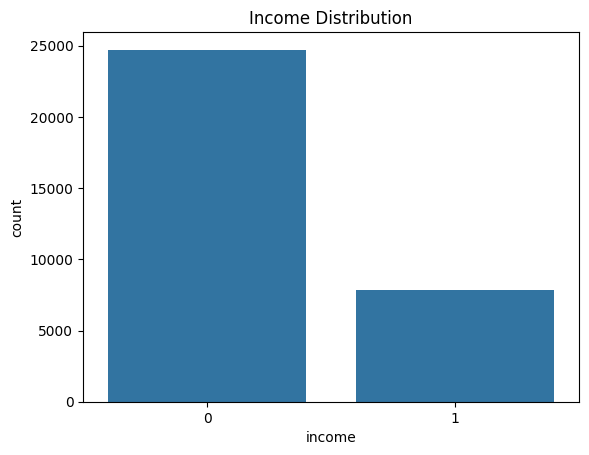

In [ ]:
sns.countplot(x='income',data=df)
plt.title("Income Distribution")
plt.show()

##age distribution histogram

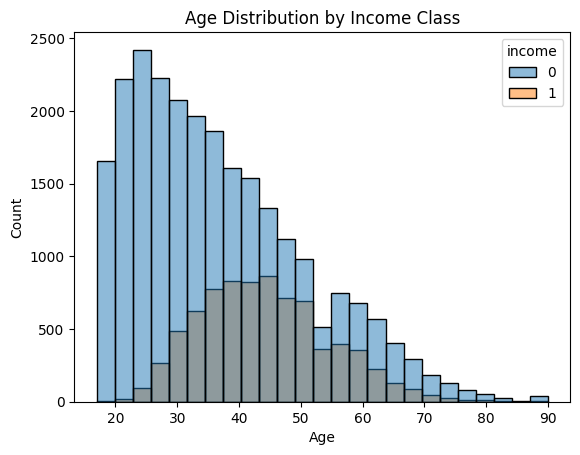

In [ ]:
plt.figure()
sns.histplot(data=df,x="age",hue="income",bins=25)
plt.title("Age Distribution by Income Class")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

##Education vs Income
Stacked Bar Chart & 100% Stacked Bar Chart

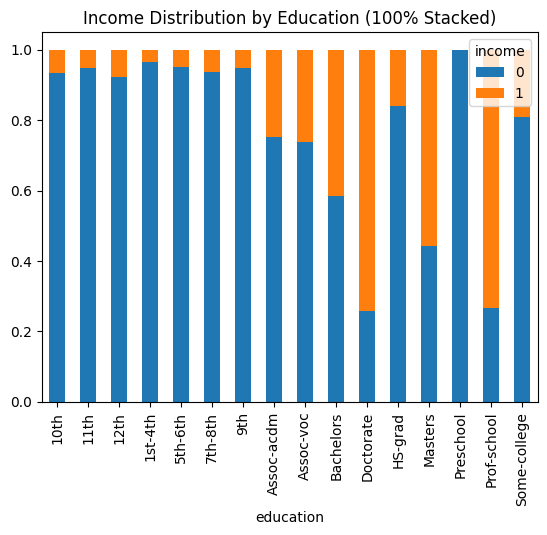

In [ ]:
ct=pd.crosstab(df['education'],df['income'],normalize='index')
ct.plot(kind='bar',stacked=True)
plt.title("Income Distribution by Education (100% Stacked)")
plt.show()

##Grouped bar chart

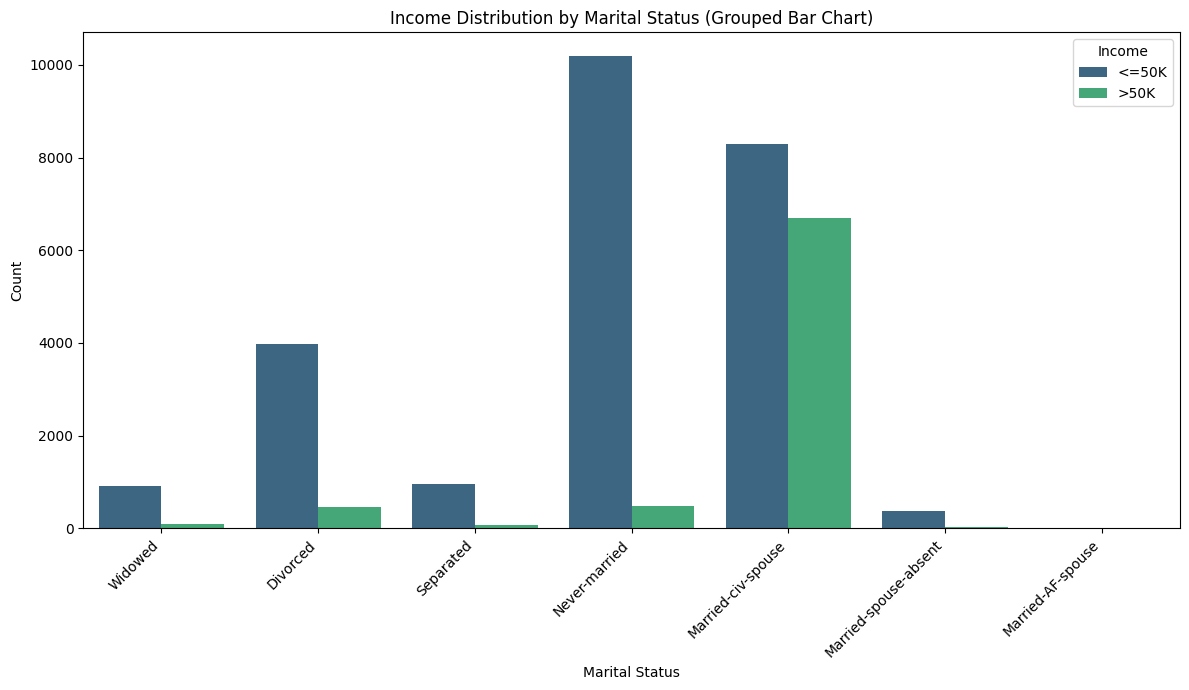

In [ ]:
plt.figure(figsize=(12, 7))
sns.countplot(data=df, x='marital.status', hue='income', palette='viridis')
plt.title('Income Distribution by Marital Status (Grouped Bar Chart)')
plt.xlabel('Marital Status')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Income', labels=['<=50K', '>50K'])
plt.tight_layout()
plt.show()

##horizontal bar chart

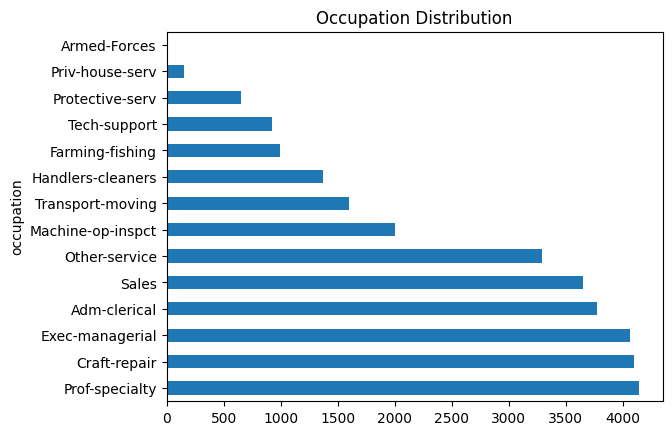

In [ ]:
df['occupation'].value_counts().plot(kind='barh')
plt.title("Occupation Distribution")
plt.show()

##density plot

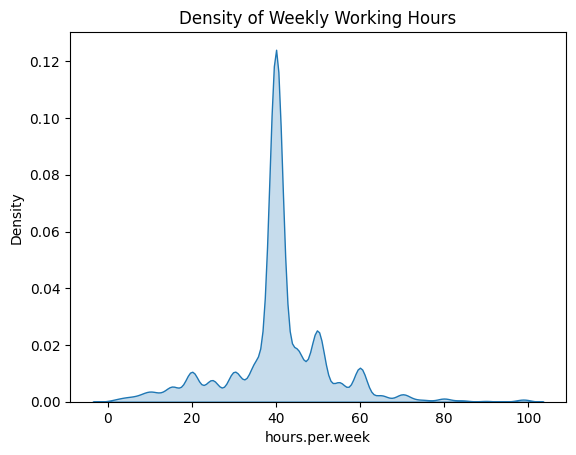

In [ ]:
sns.kdeplot(df['hours.per.week'],shade=True)
plt.title("Density of Weekly Working Hours")
plt.show()

##scatter plot

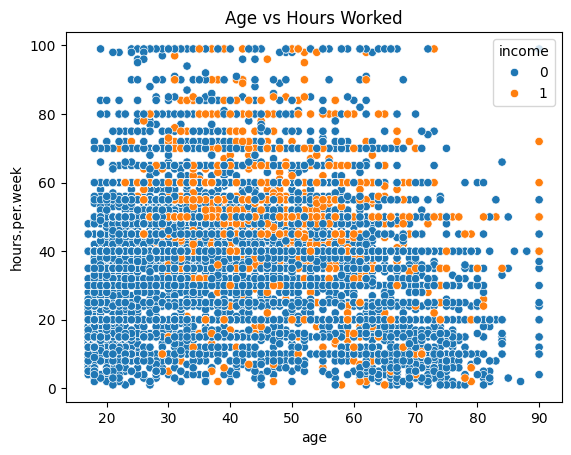

In [ ]:
sns.scatterplot(x='age',y='hours.per.week',hue='income',data=df)
plt.title("Age vs Hours Worked")
plt.show()

##bubble plot

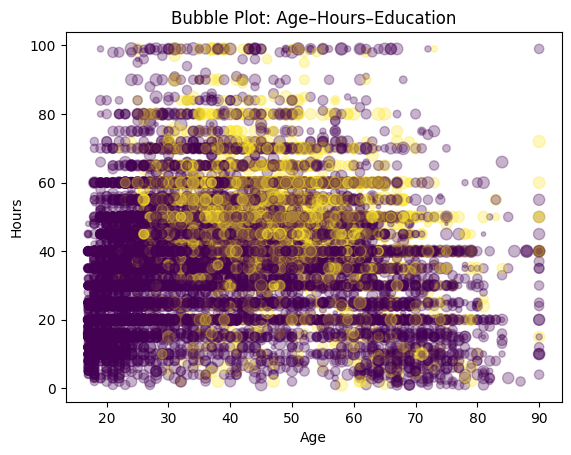

In [ ]:
plt.scatter(
    df['age'], df['hours.per.week'],
    s=df['education.num']*5,
    c=df['income'], alpha=0.3
)
plt.xlabel("Age")
plt.ylabel("Hours")
plt.title("Bubble Plot: Age–Hours–Education")
plt.show()

##pair plot

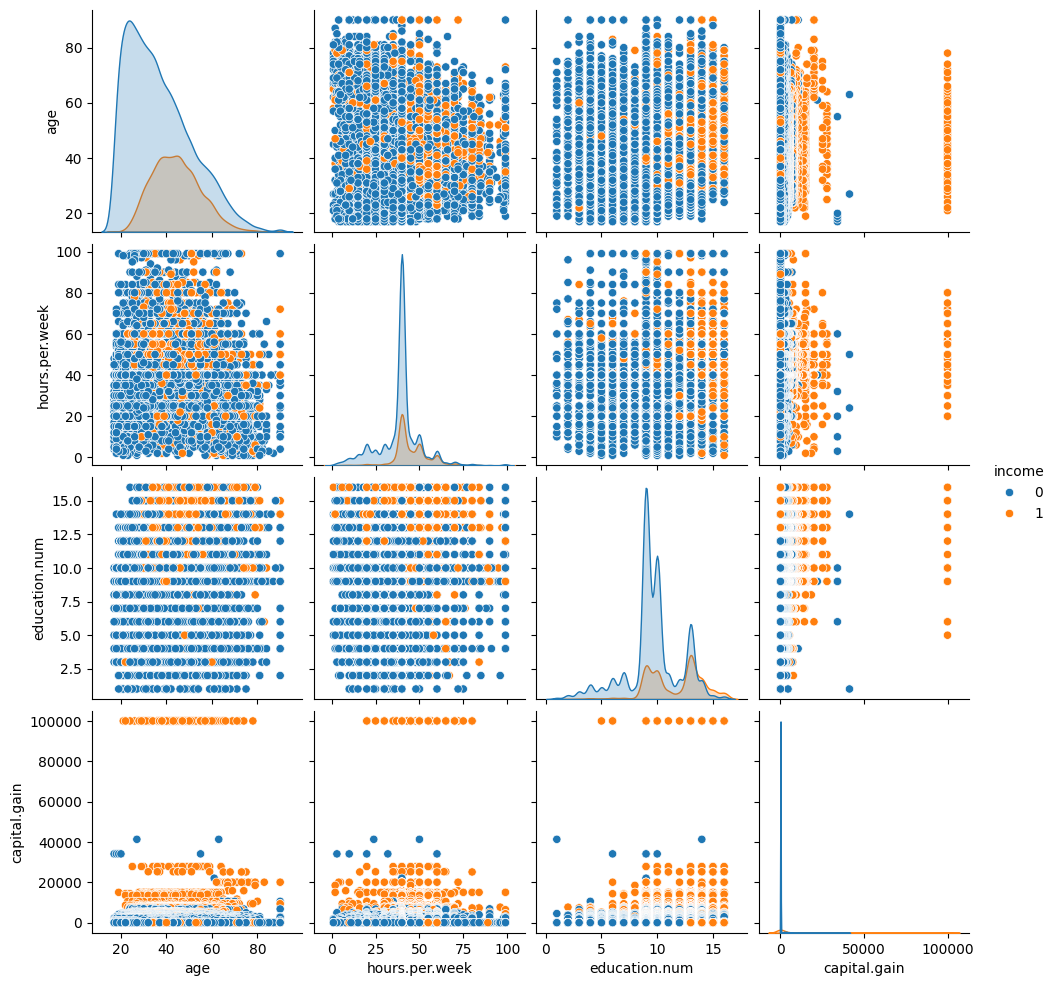

In [ ]:
sns.pairplot(
    df[['age','hours.per.week','education.num','capital.gain','income']],
    hue='income'
)
plt.show()

##correlation heatmap

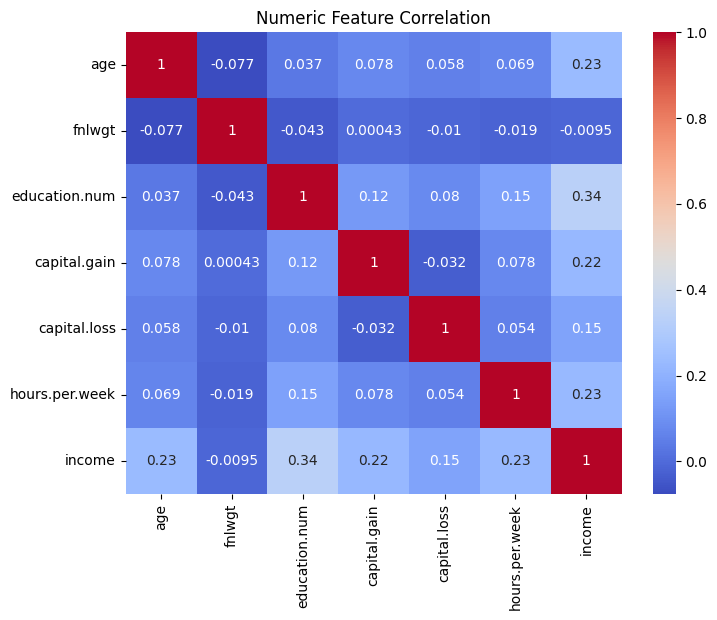

In [ ]:
numeric_cols=df.select_dtypes(include=['int64','float64'])
plt.figure(figsize=(8,6))
sns.heatmap(numeric_cols.corr(),annot=True,cmap='coolwarm')
plt.title("Numeric Feature Correlation")
plt.show()

##Handle missing values

##one hot encoding

In [ ]:
X = df.drop("income", axis=1)
y = df["income"]
categorical_cols = X.select_dtypes(include="object").columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, dummy_na=True)

##Identify columns for imputation

In [ ]:
workclass_cols=[c for c in X_encoded.columns if c.startswith("workclass_")]
occupation_cols=[c for c in X_encoded.columns if c.startswith("occupation_")]
country_cols=[c for c in X_encoded.columns if c.startswith("native.country_")]

##Apply Knn

In [ ]:
from sklearn.impute import KNNImputer
knn_imputer=KNNImputer(n_neighbors=5)
X_encoded[workclass_cols+occupation_cols]=knn_imputer.fit_transform(
    X_encoded[workclass_cols+occupation_cols]
)

##Apply iterative

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
iter_imputer=IterativeImputer(random_state=42)
X_encoded[country_cols]=iter_imputer.fit_transform(
    X_encoded[country_cols]
)

In [ ]:
final_df = pd.concat([X_encoded, y], axis=1)
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0


In [ ]:
len(final_df.columns)

114

In [ ]:
final_df.isnull().sum()

,0
age,0
fnlwgt,0
education.num,0
capital.gain,0
capital.loss,0
...,...
native.country_United-States,0
native.country_Vietnam,0
native.country_Yugoslavia,0
native.country_nan,0


In [ ]:
df.shape

(32561, 15)

In [ ]:
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,0
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,0
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,0
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,0


In [ ]:
num_cols=[
    "age",
    "fnlwgt",
    "education.num",
    "capital.gain",
    "capital.loss",
    "hours.per.week"
]
outlier_summary={}
for col in num_cols:
    Q1=final_df[col].quantile(0.25)
    Q3=final_df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=final_df[(final_df[col]<lower) | (final_df[col]>upper)]
    outlier_summary[col]=len(outliers)
    print(f"{col}")
    print(f"lower:{lower:.2f}")
    print(f"upper:{upper:.2f}")
    print(f"outliers:{len(outliers)}")


age
lower:-2.00
upper:78.00
outliers:143
fnlwgt
lower:-61009.00
upper:415887.00
outliers:992
education.num
lower:4.50
upper:16.50
outliers:1198
capital.gain
lower:0.00
upper:0.00
outliers:2712
capital.loss
lower:0.00
upper:0.00
outliers:1519
hours.per.week
lower:32.50
upper:52.50
outliers:9008


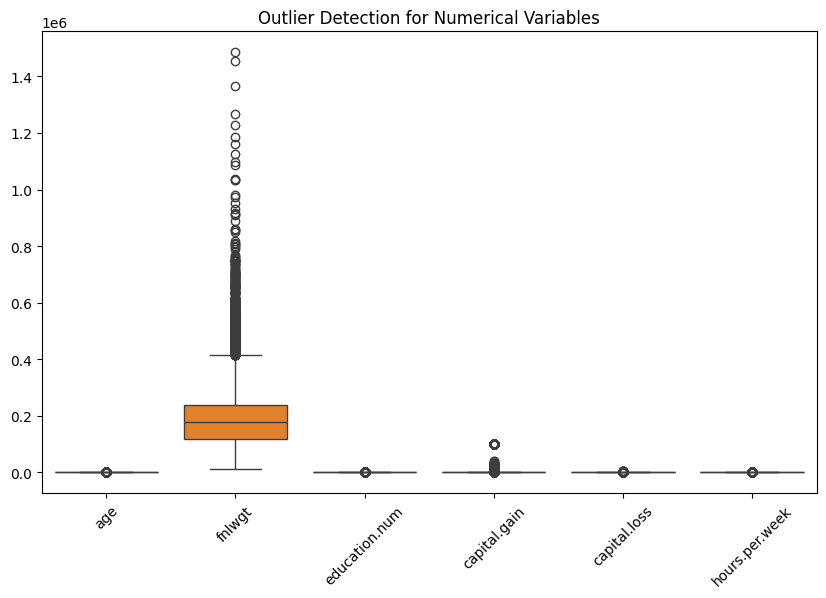

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=final_df[num_cols])
plt.xticks(rotation=45)
plt.title("Outlier Detection for Numerical Variables")
plt.show()

In [ ]:
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,0
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,0
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,0
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,0


##polynomial feature

In [ ]:
final_df['age_squared']=final_df['age']**2
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,8100
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,6724
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,4356
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2916
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,1681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,484
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,729
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,1600
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,3364


##domain specific features

In [ ]:
final_df['capital_total']=final_df['capital.gain']-final_df['capital.loss']
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,8100,-4356
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,6724,-4356
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,4356,-4356
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,2916,-3900
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,1681,-3900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,484,0
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,729,0
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,1600,0
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,3364,0


##log transformation

In [ ]:
final_df['log_capital_gain']=np.log1p(final_df['capital.gain'])
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total,log_capital_gain
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,8100,-4356,0.0
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,6724,-4356,0.0
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,4356,-4356,0.0
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,2916,-3900,0.0
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,1681,-3900,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,484,0,0.0
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,729,0,0.0
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1,1600,0,0.0
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0,3364,0,0.0


##normalaization

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
final_df[['age_norm']]=scaler.fit_transform(final_df[['age']])
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total,log_capital_gain,age_norm
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0,8100,-4356,0.0,1.000000
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,6724,-4356,0.0,0.890411
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0,4356,-4356,0.0,0.671233
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,2916,-3900,0.0,0.506849
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,1681,-3900,0.0,0.328767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,484,0,0.0,0.068493
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,729,0,0.0,0.136986
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1,1600,0,0.0,0.315068
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0,3364,0,0.0,0.561644


##standarization

In [ ]:
std_scaler=StandardScaler()
final_df[['hours_std']]=std_scaler.fit_transform(final_df[['hours.per.week']])
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total,log_capital_gain,age_norm,hours_std
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0,8100,-4356,0.0,1.000000,-0.035429
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,6724,-4356,0.0,0.890411,-1.817204
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0,4356,-4356,0.0,0.671233,-0.035429
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,2916,-3900,0.0,0.506849,-0.035429
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,1681,-3900,0.0,0.328767,-0.035429
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,484,0,0.0,0.068493,-0.035429
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,729,0,0.0,0.136986,-0.197409
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1,1600,0,0.0,0.315068,-0.035429
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0,3364,0,0.0,0.561644,-0.035429


##binning with equal width

In [ ]:
final_df['age_bin_width']=pd.cut(final_df['age'],bins=5)
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Vietnam,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total,log_capital_gain,age_norm,hours_std,age_bin_width
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,8100,-4356,0.0,1.000000,-0.035429,"(75.4, 90.0]"
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,6724,-4356,0.0,0.890411,-1.817204,"(75.4, 90.0]"
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,4356,-4356,0.0,0.671233,-0.035429,"(60.8, 75.4]"
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,2916,-3900,0.0,0.506849,-0.035429,"(46.2, 60.8]"
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,1681,-3900,0.0,0.328767,-0.035429,"(31.6, 46.2]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,484,0,0.0,0.068493,-0.035429,"(16.927, 31.6]"
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,729,0,0.0,0.136986,-0.197409,"(16.927, 31.6]"
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1,1600,0,0.0,0.315068,-0.035429,"(31.6, 46.2]"
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0,3364,0,0.0,0.561644,-0.035429,"(46.2, 60.8]"


##binning with equal freq

In [ ]:
final_df['age_bin_freq']=pd.qcut(final_df['age'],q=5)
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Yugoslavia,native.country_nan,income,age_squared,capital_total,log_capital_gain,age_norm,hours_std,age_bin_width,age_bin_freq
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0,8100,-4356,0.0,1.000000,-0.035429,"(75.4, 90.0]","(50.0, 90.0]"
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0.0,0,6724,-4356,0.0,0.890411,-1.817204,"(75.4, 90.0]","(50.0, 90.0]"
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0.0,0,4356,-4356,0.0,0.671233,-0.035429,"(60.8, 75.4]","(50.0, 90.0]"
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0,2916,-3900,0.0,0.506849,-0.035429,"(46.2, 60.8]","(50.0, 90.0]"
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0,1681,-3900,0.0,0.328767,-0.035429,"(31.6, 46.2]","(33.0, 41.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0,484,0,0.0,0.068493,-0.035429,"(16.927, 31.6]","(16.999, 26.0]"
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0.0,0,729,0,0.0,0.136986,-0.197409,"(16.927, 31.6]","(26.0, 33.0]"
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,1,1600,0,0.0,0.315068,-0.035429,"(31.6, 46.2]","(33.0, 41.0]"
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0.0,0,3364,0,0.0,0.561644,-0.035429,"(46.2, 60.8]","(50.0, 90.0]"


#custom binning

In [ ]:
final_df['age_group']=pd.cut(
    final_df['age'],bins=[0,25,40,60,100],labels=['Young','Mid','Senior','Old']
)
final_df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_nan,income,age_squared,capital_total,log_capital_gain,age_norm,hours_std,age_bin_width,age_bin_freq,age_group
0,90,77053,9,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0,8100,-4356,0.0,1.000000,-0.035429,"(75.4, 90.0]","(50.0, 90.0]",Old
1,82,132870,9,0,4356,18,0.0,0.0,0.0,1.0,...,0.0,0,6724,-4356,0.0,0.890411,-1.817204,"(75.4, 90.0]","(50.0, 90.0]",Old
2,66,186061,10,0,4356,40,0.0,0.0,0.0,0.0,...,0.0,0,4356,-4356,0.0,0.671233,-0.035429,"(60.8, 75.4]","(50.0, 90.0]",Old
3,54,140359,4,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0,2916,-3900,0.0,0.506849,-0.035429,"(46.2, 60.8]","(50.0, 90.0]",Senior
4,41,264663,10,0,3900,40,0.0,0.0,0.0,1.0,...,0.0,0,1681,-3900,0.0,0.328767,-0.035429,"(31.6, 46.2]","(33.0, 41.0]",Senior
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0,484,0,0.0,0.068493,-0.035429,"(16.927, 31.6]","(16.999, 26.0]",Young
32557,27,257302,12,0,0,38,0.0,0.0,0.0,1.0,...,0.0,0,729,0,0.0,0.136986,-0.197409,"(16.927, 31.6]","(26.0, 33.0]",Mid
32558,40,154374,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,1,1600,0,0.0,0.315068,-0.035429,"(31.6, 46.2]","(33.0, 41.0]",Mid
32559,58,151910,9,0,0,40,0.0,0.0,0.0,1.0,...,0.0,0,3364,0,0.0,0.561644,-0.035429,"(46.2, 60.8]","(50.0, 90.0]",Senior


##feature selection

In [ ]:
final_df.select_dtypes(include=['number']).corr()['income'].sort_values(ascending=False)

,income
income,1.000000
education.num,0.335154
log_capital_gain,0.289462
age_norm,0.234037
age,0.234037
...,...
workclass_Private,-0.078528
occupation_nan,-0.078583
occupation_Handlers-cleaners,-0.087265
occupation_Adm-clerical,-0.089986


##rfa

In [ ]:
from sklearn.feature_selection import RFE

X=final_df.drop(['income', 'age_bin_width', 'age_bin_freq', 'age_group'], axis=1)
y=final_df['income']
model=LogisticRegression(max_iter=1000)
rfe = RFE(model, n_features_to_select=8)
rfe.fit(X, y)
rfe_results = pd.DataFrame({
    'Feature': X.columns,
    'Selected': rfe.support_,
    'Ranking': rfe.ranking_
}).sort_values(by='Ranking')
rfe_results

,Feature,Selected,Ranking
18,education_1st-4th,True,1
19,education_5th-6th,True,1
34,marital.status_Married-civ-spouse,True,1
58,relationship_Own-child,True,1
49,occupation_Prof-specialty,True,1
...,...,...,...
67,race_nan,False,107
70,sex_nan,False,108
39,marital.status_nan,False,109
61,relationship_nan,False,110


##PCA

In [ ]:
from sklearn.decomposition import PCA

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
pca=PCA()
pca.fit(X_scaled)
explained_variance=pd.DataFrame({
    'Component': range(1,len(pca.explained_variance_ratio_)+1),
    'Explained Variance': pca.explained_variance_ratio_
})
explained_variance.head(10)

,Component,Explained Variance
0,1,0.046958
1,2,0.030324
2,3,0.027117
3,4,0.023105
4,5,0.021733
5,6,0.020179
6,7,0.016892
7,8,0.016572
8,9,0.014750
9,10,0.014388


##Prepare final data

In [ ]:
rfe_results[rfe_results['Selected']==True]['Feature']

,Feature
18,education_1st-4th
19,education_5th-6th
34,marital.status_Married-civ-spouse
58,relationship_Own-child
49,occupation_Prof-specialty
43,occupation_Exec-managerial
33,marital.status_Married-AF-spouse
74,native.country_Columbia


In [ ]:
X=final_df.drop(['income','age_bin_width','age_bin_freq','age_group'],axis=1)
y=final_df['income']
X_train,X_test,y_train,y_test=train_test_split(X, y,test_size=0.2, random_state=42)
rf=RandomForestClassifier(n_estimators=200,random_state=42)
rf.fit(X_train,y_train)
importances=pd.DataFrame({
    'Feature':X_train.columns,
    'Importance':rf.feature_importances_
}).sort_values(by='Importance', ascending=False)
importances.head(15)

,Feature,Importance
1,fnlwgt,0.110138
116,age_norm,0.067320
113,age_squared,0.063984
0,age,0.063288
2,education.num,0.061671
34,marital.status_Married-civ-spouse,0.058030
114,capital_total,0.053684
3,capital.gain,0.046901
5,hours.per.week,0.045107
117,hours_std,0.043023


In [ ]:
importances

,Feature,Importance
1,fnlwgt,0.110138
116,age_norm,0.067320
113,age_squared,0.063984
0,age,0.063288
2,education.num,0.061671
...,...,...
31,education_nan,0.000000
85,native.country_Holand-Netherlands,0.000000
70,sex_nan,0.000000
61,relationship_nan,0.000000


##Final features

In [ ]:
final_features=['age','age_norm','age_squared','education.num','hours.per.week',
                  'hours_std','capital_total','capital.gain','log_capital_gain',
                  'marital.status_Married-civ-spouse','relationship_Husband']
y=final_df['income']

In [ ]:
X=final_df[final_features]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,
                                                    random_state=42,stratify=y)

##define models

In [ ]:
models={"Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "SVM": SVC(probability=True, random_state=42)
        }

##5 fold cross validation

In [ ]:
cv_results=[]
for name,model in models.items():
    scores=cross_val_score(model,X_train,y_train,cv=5,scoring='roc_auc')
    cv_results.append({
        'Model': name,
        'Mean AUC': scores.mean(),
        'Std AUC': scores.std()
    })
cv_results_df=pd.DataFrame(cv_results).sort_values(by='Mean AUC',ascending=False)
cv_results_df

,Model,Mean AUC,Std AUC
3,Gradient Boosting,0.918183,0.003181
0,Logistic Regression,0.902280,0.002919
2,Random Forest,0.888299,0.003726
1,Decision Tree,0.819014,0.008606
4,SVM,0.790647,0.007495


##hyperparameter tuning

##gradient boosting

In [ ]:
from sklearn.model_selection import GridSearchCV
gb_params={
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}
gb_grid=GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=5,
    scoring='roc_auc'
)
gb_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'learning_rate': [0.05, 0.1], 'max_depth': [3, 5],
                         'n_estimators': [100, 200]},
             scoring='roc_auc')

##random forest

In [ ]:
rf_params={
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}
rf_grid=GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='roc_auc'
)
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 10], 'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='roc_auc')

##logistic regression

In [ ]:
lr_params={
    'C': [0.01, 0.1, 1, 10]
}

lr_grid=GridSearchCV(
    LogisticRegression(max_iter=1000),
    lr_params,
    cv=5,
    scoring='roc_auc'
)
lr_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.01, 0.1, 1, 10]}, scoring='roc_auc')

##final model comparison

In [ ]:
final_models={
    "Gradient Boosting": gb_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Logistic Regression": lr_grid.best_estimator_
}
final_results=[]
for name, model in final_models.items():
    model.fit(X_train, y_train)
    y_pred_prob=model.predict_proba(X_test)[:, 1]
    auc=roc_auc_score(y_test, y_pred_prob)
    final_results.append({
        'Model': name,
        'Test AUC': auc
    })
pd.DataFrame(final_results)

,Model,Test AUC
0,Gradient Boosting,0.914874
1,Random Forest,0.908924
2,Logistic Regression,0.895530


##fit final model

In [ ]:
best_model=gb_grid.best_estimator_
best_model.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, max_depth=5, n_estimators=200,
                           random_state=42)

##prediction

In [ ]:
y_pred=best_model.predict(X_test)
y_pred_prob=best_model.predict_proba(X_test)[:, 1]

In [ ]:
y_pred_prob[:10]

array([0.10092992, 0.00241503, 0.75002545, 0.47891757, 0.02857052,
       0.33931643, 0.14954553, 0.13915681, 0.07776042, 0.02546809])

##confusion matrix

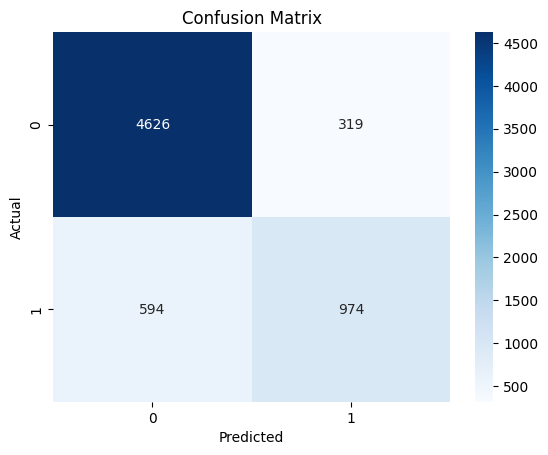

In [ ]:
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

##classification matrix

In [ ]:
accuracy=accuracy_score(y_test, y_pred)
precision=precision_score(y_test, y_pred)
recall=recall_score(y_test, y_pred)
f1=f1_score(y_test, y_pred)

accuracy,precision,recall,f1

(0.8598188238906802,
 0.7532869296210364,
 0.6211734693877551,
 0.6808808109052779)

##roc curve

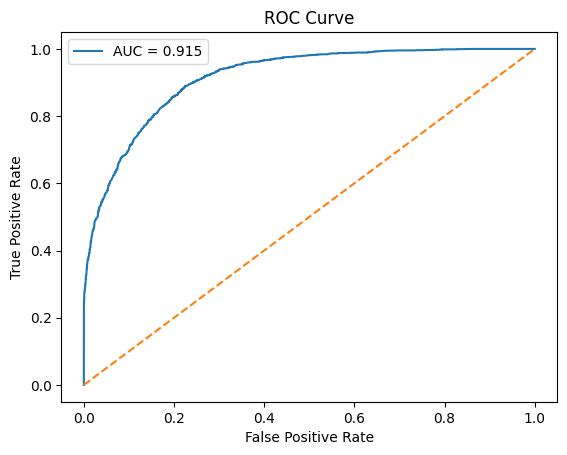

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc=roc_auc_score(y_test, y_pred_prob)
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1],linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [ ]:
!pip install shap

In [ ]:
import shap
X_train_f=X_train.astype("float64")
X_test_f=X_test.astype("float64")

explainer=shap.Explainer(best_model,X_train_f)
shap_values= xplainer(X_test_f,check_additivity=False)


 99%|===================| 6464/6513 [00:38<00:00]       

##shap summary plot

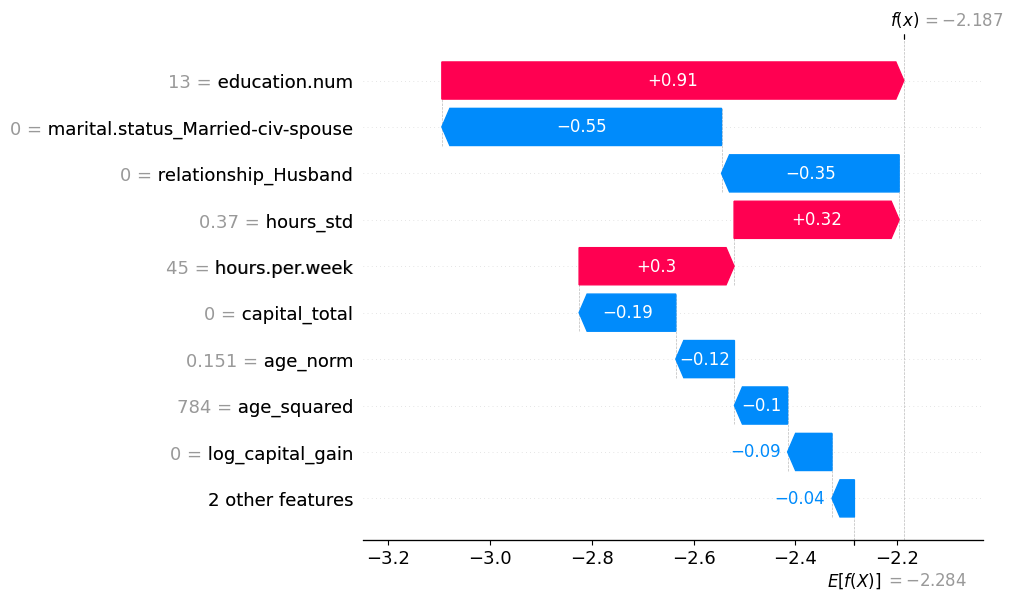

In [ ]:
shap.plots.waterfall(shap_values[0])

##make a prediction

In [ ]:
sample_person=pd.DataFrame([{
    'age':45,
    'age_norm':0.55,
    'age_squared':45**2,
    'education.num':13,
    'hours.per.week':45,
    'hours_std':0.60,
    'capital_total':5000,
    'capital.gain':5000,
    'log_capital_gain':np.log1p(5000),
    'marital.status_Married-civ-spouse':1,
    'relationship_Husband':1
}])

In [ ]:
prediction = best_model.predict(sample_person)
prediction_proba = best_model.predict_proba(sample_person)


In [ ]:
if prediction[0]==1:
    print("Predicted income: >50K")
else:
    print("Predicted income: ≤50K")

print("Probability of >50K:",prediction_proba[0][1])


Predicted income: ≤50K
Probability of >50K: 0.24252432565395235


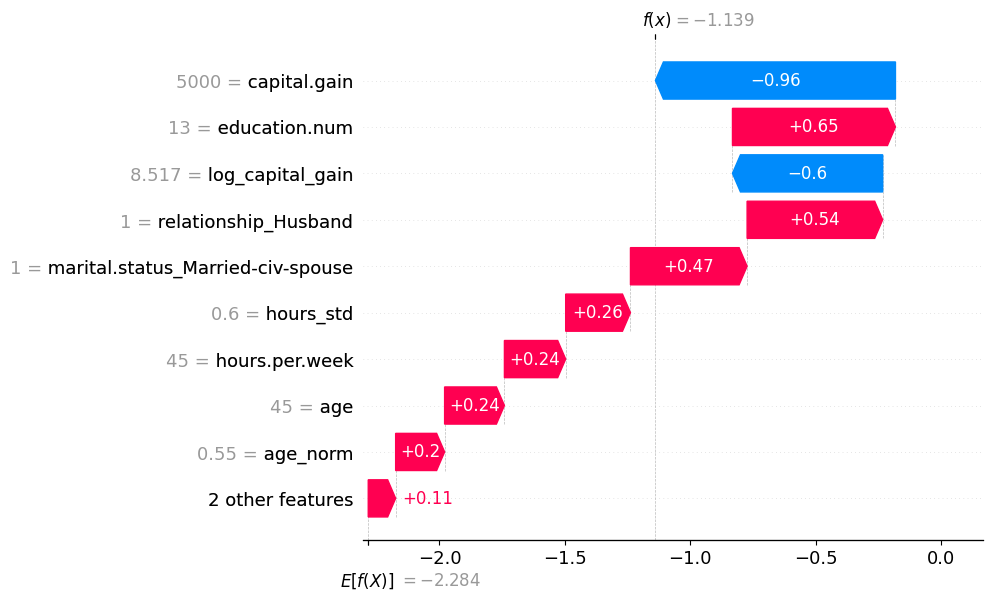

In [ ]:
explainer=shap.Explainer(best_model, X_train_f)
shap_values=explainer(sample_person)
shap.plots.waterfall(shap_values[0])
#Blue bars → push income down
#Red bars → push income up